In [1]:
import os
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'pancan')
pth_spec = os.path.join('..', 'spec')
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'pancan')

In [3]:
# load agentic manifold analysis
fn = os.path.join(pth_spec, 'log.csv')
df = pd.read_csv(fn).set_index('JoinKey')

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata = adata[adata.obs.Name.isin(df.index)]
adata = sc.get.aggregate(adata, 'Name', 'mean')
adata.obs = adata.obs.join(df, 'Name'); adata

AnnData object with n_obs × n_vars = 86 × 245
    obs: 'Name', 'Title', 'Category', 'Disease', 'Run start', 'Run end', 'Expert interaction', 'Manifold geometry', 'Gate 1', 'Gate 2', 'Gate 3', 'Hub r', 'Attempts'
    layers: 'mean'

In [5]:
cols = ['Category', 'Disease']
var = ['Manifold geometry', 'Attempts']

# manifold counts (per disease) -> dot sizes
grp = adata.obs.groupby(cols, observed = True)
get_count = lambda sdf: (~sdf[var[0]].isna()).sum()
df_size = (grp.apply(get_count, include_groups = False)
           .rename(var[0]).to_frame()
           .reset_index(level = cols[0], drop = True))
df_size.value_counts(sort = False)

Manifold geometry
0                     4
1                    25
2                     6
3                     3
4                     2
5                     3
Name: count, dtype: int64

In [6]:
# agentic attempts (mean) -> dot colors
get_mean = lambda sdf: sdf[var[1]].mean()
df_color = (grp.apply(get_mean, include_groups = False)
            .rename(var[0]).to_frame()
            .reset_index(level = cols[0], drop = True))
(df_color // 1).value_counts(sort = False)

Manifold geometry
1.0                  23
2.0                   8
3.0                   6
4.0                   1
6.0                   1
7.0                   1
10.0                  2
Name: count, dtype: int64

/home/caleb/miniconda3/envs/scanpy/lib/python3.13/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


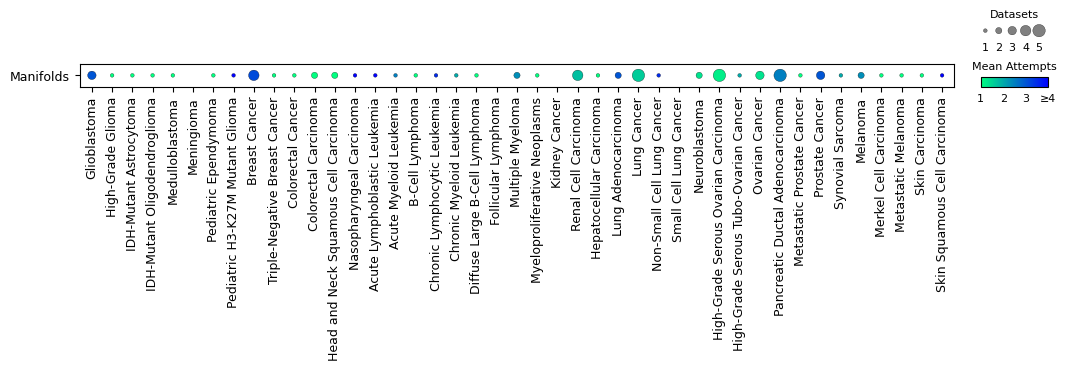

In [12]:
# prepare dummy adata for dotplot
df_size = df_size / df_size.max()  # as proportions
df_plt = pd.concat((df_size, df_color), axis = 1)
obs = pd.DataFrame(df_plt.index)
adata_plt = ad.AnnData(X = df_plt.values, obs = obs)
adata_plt.var_names = pd.Index(var)

# manifold dotplot
fs1, fs2, vlim = 9, 8, [1, 4]
dp = sc.pl.DotPlot(adata_plt, var[0], cols[1],
                   categories_order = df_plt.index,
                   dot_color_df = df_color,
                   dot_size_df = df_size,
                   vmin = vlim[0], vmax = vlim[1],
                   cmap = 'winter_r', figsize = (12.5, .3)
                   ).swap_axes()

dp.style(largest_dot = 80,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('Datasets', size = fs2, pad = -5.5)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = 3.75)
ax_size.set_xticklabels(['1', '2', '3', '4', '5'])
cax.set_title('Mean Attempts', size = fs2, pad = 5)
xticks = np.arange(vlim[0], vlim[1] + .1)
cax.set_xticks(xticks, ['1', '2', '3', '≥4'])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 5)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_size.x0,
                      pos_main.y0 + 2.15 * pos_main.height,
                      pos_size.width,
                      5 * pos_size.height])

cax.set_position([pos_color.x0,
                  pos_main.y0 + .01 * pos_main.height,
                  pos_color.width,
                  6 * pos_color.height])

ax_main.set_yticklabels(['Manifolds'], fontsize = fs1)
ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        fontsize = fs1)

fn = os.path.join(pth_out, 'manifolds.pdf')
plt.savefig(fn, bbox_inches = 'tight')